# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'siyaoxu2'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

256 epochs over 954 days; median quoted error 0.040 mag; rms of the light curve 0.215 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


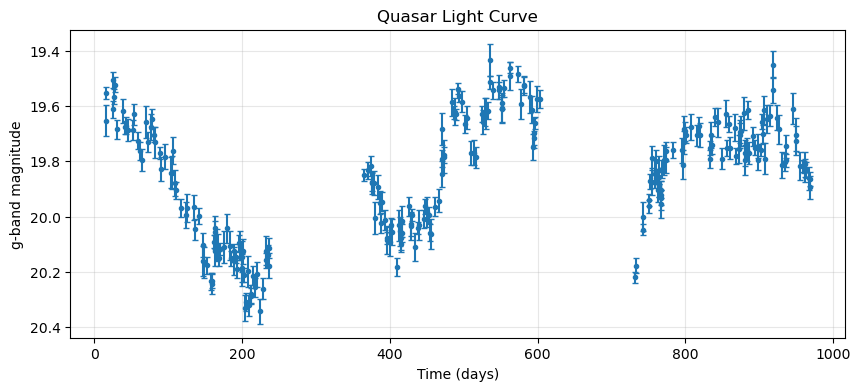

Highest peak period: 264.95 days
Peak power: 0.5385
False-alarm probability: 2.8193e-39


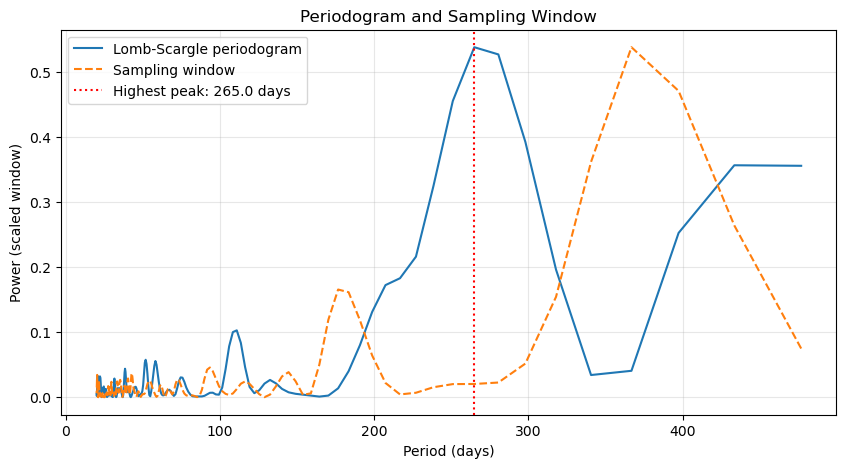

In [14]:
# Part 1: your work here

# Part 1: Light curve, periodogram, and window function

# Plot the light curve
plt.figure(figsize=(10, 4))
plt.errorbar(t, y, yerr=e, fmt='.', capsize=2)
plt.gca().invert_yaxis()
plt.xlabel('Time (days)')
plt.ylabel('g-band magnitude')
plt.title('Quasar Light Curve')
plt.grid(alpha=0.3)
plt.show()

# Frequency grid: periods from 20 days to T/2
f_min = 2 / T
f_max = 1 / 20
df = 1 / (5 * T)
freq = np.arange(f_min, f_max + df / 2, df)
period = 1 / freq

# Lomb-Scargle periodogram with measurement errors
ls = LombScargle(t, y, dy=e)
power = ls.power(freq)

# Sampling window function
window_ls = LombScargle(
    t, np.ones_like(y),
    fit_mean=False,
    center_data=False
)
window = window_ls.power(freq)

# Scale window to the same maximum
window = window / np.max(window) * np.max(power)

# Highest peak and false-alarm probability
idx = np.argmax(power)
best_period = period[idx]
best_power = power[idx]
fap = ls.false_alarm_probability(best_power)

print(f"Highest peak period: {best_period:.2f} days")
print(f"Peak power: {best_power:.4f}")
print(f"False-alarm probability: {fap:.4e}")

# Plot periodogram and window function
plt.figure(figsize=(10, 5))
plt.plot(period, power, label='Lomb-Scargle periodogram')
plt.plot(period, window, '--', label='Sampling window')
plt.axvline(best_period, color='red', linestyle=':',
            label=f'Highest peak: {best_period:.1f} days')
plt.xlabel('Period (days)')
plt.ylabel('Power (scaled window)')
plt.title('Periodogram and Sampling Window')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**ANSWER (a few sentences):**

The highest peak in the Lomb–Scargle periodogram occurs at **264.95 days**, with a peak power of **0.5385** and a false-alarm probability of **2.8193 × 10⁻³⁹**. The sampling window shows a strong peak near 365 days due to seasonal observing gaps. Other peaks, including those near 110 days and 430–470 days, may be aliases or arise from long-term stochastic variability, although their origins cannot be determined from this plot alone.

We do not search beyond T/2 (477 days) because longer periods would cover fewer than two complete cycles, making it difficult to distinguish periodic signals from long-term variability.

Astropy's false-alarm probability assumes independent Gaussian (white) noise with the specified measurement uncertainties. However, quasars exhibit correlated red noise, so the extremely small FAP does not necessarily indicate a real periodic signal.

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ 0.208 (+0.071 / −0.036) mag, $\tau = $ 105.9 (+88.5 / −35.5) d, $T/\tau = $ 9.007; the exponential kernel beats the squared exponential by $\Delta\ln L = $ 38.111; 31 of 47 held-out points are inside the 68% band.


DRW / exponential kernel
mu = 19.8301 mag
sigma = 0.2081 mag
tau = 105.90 days
Maximum logL = 338.4215
T/tau = 9.007
LogL from different starts: [338.4215149306591, 338.4215149293308, 338.4215149309457, 338.4215149309483, 338.42151493083725]

68% profile likelihood intervals
sigma = 0.2081 (+0.0706/-0.0362) mag
tau = 105.90 (+88.55/-35.46) days


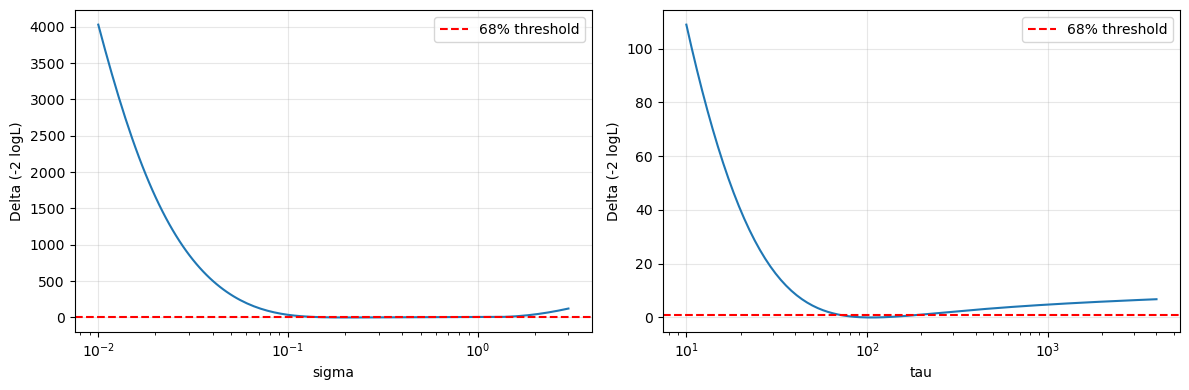


Kernel comparison
Exponential max logL: 338.4215
Squared-exp max logL: 300.3109
Delta logL (exp - sqexp): 38.1107
Best kernel: exp


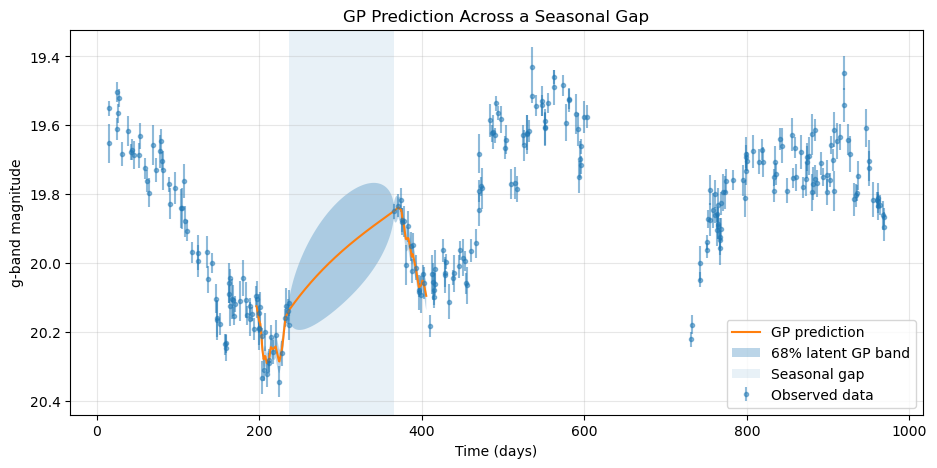


Seasonal gap: 236.4 to 365.4 d
Band represents the latent light curve (no measurement noise).

Held-out blocks: [201.2 487.8 766.8 866.9]
Number held out: 47
Number training: 209

exp kernel
Held-out points: 47
Inside 68% band: 31 / 47
Fraction: 0.660
R^2: 0.8839

sqexp kernel
Held-out points: 47
Inside 68% band: 24 / 47
Fraction: 0.511
R^2: 0.6994


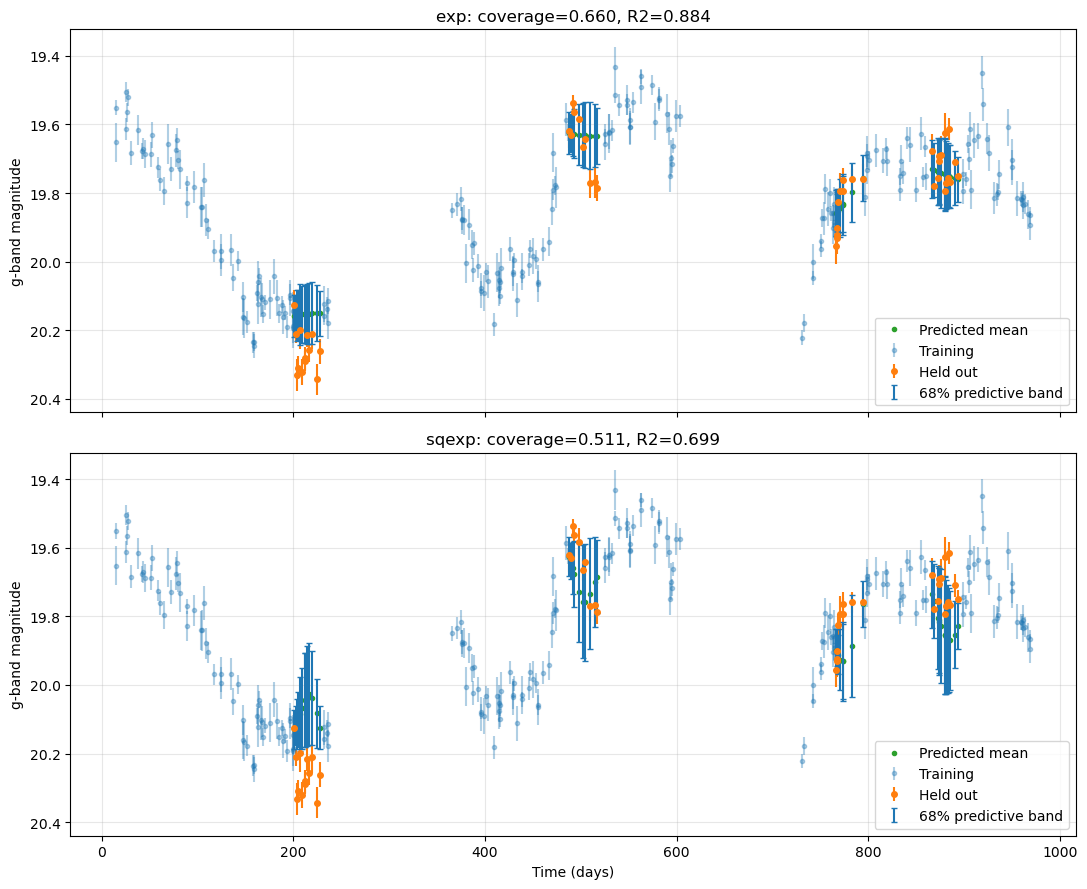


========== FINAL ANSWER ==========
sigma = 0.208 (+0.071/-0.036) mag
tau = 105.9 (+88.5/-35.5) d
T/tau = 9.007
Delta ln L (exp - sqexp) = 38.111
Exponential coverage: 31/47
Squared-exponential coverage: 24/47


In [15]:
# Part 2: your work here

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import chi2

# Sort observations by time
order = np.argsort(t)
t, y, e = t[order], y[order], e[order]
T = np.ptp(t)

# Priors: uniform in log(sigma), log(tau)
LOG_SIG_BOUNDS = (np.log(0.01), np.log(3.0))
LOG_TAU_BOUNDS = (np.log(10.0), np.log(4000.0))
BOUNDS = [LOG_SIG_BOUNDS, LOG_TAU_BOUNDS]

def covariance(t1, t2, sigma, tau, kernel="exp"):
    dt = np.abs(np.subtract.outer(t1, t2))
    if kernel == "exp":
        return sigma**2 * np.exp(-dt / tau)
    elif kernel == "sqexp":
        return sigma**2 * np.exp(-0.5 * (dt / tau)**2)
    else:
        raise ValueError("Unknown kernel")

def gp_loglike(theta, tdata, ydata, edata, kernel="exp",
               return_mu=False):
    log_sigma, log_tau = theta

    if not (LOG_SIG_BOUNDS[0] <= log_sigma <= LOG_SIG_BOUNDS[1]
            and LOG_TAU_BOUNDS[0] <= log_tau <= LOG_TAU_BOUNDS[1]):
        return -np.inf

    sigma, tau = np.exp(theta)
    C = covariance(tdata, tdata, sigma, tau, kernel)
    C[np.diag_indices_from(C)] += edata**2

    try:
        cf = cho_factor(C, lower=True, check_finite=False)
        ones = np.ones(len(ydata))

        # Analytically maximize over constant mean mu
        inv_y = cho_solve(cf, ydata, check_finite=False)
        inv_one = cho_solve(cf, ones, check_finite=False)
        mu = np.dot(ones, inv_y) / np.dot(ones, inv_one)

        residual = ydata - mu
        alpha = cho_solve(cf, residual, check_finite=False)

        logdet = 2 * np.sum(np.log(np.diag(cf[0])))
        N = len(ydata)

        logL = -0.5 * (
            residual @ alpha + logdet + N * np.log(2 * np.pi)
        )

        if return_mu:
            return logL, mu
        return logL

    except np.linalg.LinAlgError:
        return (-np.inf, np.nan) if return_mu else -np.inf

def log_prior(theta):
    if (LOG_SIG_BOUNDS[0] <= theta[0] <= LOG_SIG_BOUNDS[1]
        and LOG_TAU_BOUNDS[0] <= theta[1] <= LOG_TAU_BOUNDS[1]):
        return -np.log(
            LOG_SIG_BOUNDS[1] - LOG_SIG_BOUNDS[0]
        ) - np.log(
            LOG_TAU_BOUNDS[1] - LOG_TAU_BOUNDS[0]
        )
    return -np.inf

def log_posterior(theta, tdata, ydata, edata, kernel="exp"):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gp_loglike(theta, tdata, ydata, edata, kernel)

# Multiple starting values for MLE
starts = [
    (0.10, 30),
    (0.20, 100),
    (0.30, 300),
    (0.50, 1000),
    (1.00, 3000)
]

def fit_gp(tdata, ydata, edata, kernel="exp"):
    results = []

    for s, tau0 in starts:
        result = minimize(
            lambda x: -gp_loglike(
                x, tdata, ydata, edata, kernel
            ),
            x0=np.log([s, tau0]),
            bounds=BOUNDS,
            method="L-BFGS-B"
        )
        if result.success and np.isfinite(result.fun):
            results.append(result)

    if not results:
        raise RuntimeError("All fits failed")

    best = min(results, key=lambda r: r.fun)
    logL, mu = gp_loglike(
        best.x, tdata, ydata, edata, kernel,
        return_mu=True
    )

    return {
        "sigma": np.exp(best.x[0]),
        "tau": np.exp(best.x[1]),
        "mu": mu,
        "logL": logL,
        "theta": best.x,
        "starts_logL": [-r.fun for r in results]
    }

# ==========================================
# 2.2 Fit DRW and estimate uncertainties
# ==========================================

fit_exp = fit_gp(t, y, e, "exp")

print("DRW / exponential kernel")
print(f"mu = {fit_exp['mu']:.4f} mag")
print(f"sigma = {fit_exp['sigma']:.4f} mag")
print(f"tau = {fit_exp['tau']:.2f} days")
print(f"Maximum logL = {fit_exp['logL']:.4f}")
print(f"T/tau = {T / fit_exp['tau']:.3f}")
print("LogL from different starts:", fit_exp["starts_logL"])

# Profile likelihood in log(tau)
# Optimize over log(sigma) at each fixed tau
def profile_logL(values, fixed_index, kernel="exp"):
    profile = []
    other_index = 1 - fixed_index

    for value in values:
        def objective(other):
            theta = np.empty(2)
            theta[fixed_index] = value
            theta[other_index] = other
            return -gp_loglike(theta, t, y, e, kernel)

        result = minimize_scalar(
            objective,
            bounds=BOUNDS[other_index],
            method="bounded",
            options={"xatol": 1e-4}
        )
        profile.append(-result.fun)

    return np.array(profile)

tau_grid = np.linspace(*LOG_TAU_BOUNDS, 180)
sig_grid = np.linspace(*LOG_SIG_BOUNDS, 140)

profile_tau = profile_logL(tau_grid, 1)
profile_sig = profile_logL(sig_grid, 0)

# 68% interval: Delta(-2 logL) = 1
def profile_interval(grid, profile, max_logL):
    mask = 2 * (max_logL - profile) <= 1.0

    if not np.any(mask):
        raise RuntimeError("No points inside profile interval")

    indices = np.flatnonzero(mask)
    lo = indices[0]
    hi = indices[-1]

    # Interpolate threshold crossings
    threshold = max_logL - 0.5

    left = grid[lo]
    right = grid[hi]

    if lo > 0:
        left = np.interp(
            threshold,
            [profile[lo-1], profile[lo]],
            [grid[lo-1], grid[lo]]
        )

    if hi < len(grid) - 1:
        right = np.interp(
            threshold,
            [profile[hi+1], profile[hi]],
            [grid[hi+1], grid[hi]]
        )

    return np.exp(left), np.exp(right)

sig_lo, sig_hi = profile_interval(
    sig_grid, profile_sig, fit_exp["logL"]
)
tau_lo, tau_hi = profile_interval(
    tau_grid, profile_tau, fit_exp["logL"]
)

print("\n68% profile likelihood intervals")
print(
    f"sigma = {fit_exp['sigma']:.4f} "
    f"(+{sig_hi-fit_exp['sigma']:.4f}/"
    f"-{fit_exp['sigma']-sig_lo:.4f}) mag"
)
print(
    f"tau = {fit_exp['tau']:.2f} "
    f"(+{tau_hi-fit_exp['tau']:.2f}/"
    f"-{fit_exp['tau']-tau_lo:.2f}) days"
)

# Plot profile likelihoods
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, grid, prof, name in [
    (axes[0], sig_grid, profile_sig, "sigma"),
    (axes[1], tau_grid, profile_tau, "tau")
]:
    delta = 2 * (fit_exp["logL"] - prof)
    ax.plot(np.exp(grid), delta)
    ax.axhline(1, color="red", linestyle="--",
               label="68% threshold")
    ax.set_xscale("log")
    ax.set_xlabel(name)
    ax.set_ylabel("Delta (-2 logL)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 2.3 Compare exponential vs squared-exponential
# ==========================================

fit_sq = fit_gp(t, y, e, "sqexp")
delta_logL = fit_exp["logL"] - fit_sq["logL"]

print("\nKernel comparison")
print(f"Exponential max logL: {fit_exp['logL']:.4f}")
print(f"Squared-exp max logL: {fit_sq['logL']:.4f}")
print(f"Delta logL (exp - sqexp): {delta_logL:.4f}")

best_kernel = "exp" if delta_logL >= 0 else "sqexp"
best_fit = fit_exp if delta_logL >= 0 else fit_sq

print("Best kernel:", best_kernel)

# ==========================================
# GP prediction function
# ==========================================

def gp_predict(t_train, y_train, e_train, t_pred,
               fit, kernel, e_pred=None):
    sigma = fit["sigma"]
    tau = fit["tau"]
    mu = fit["mu"]

    C = covariance(t_train, t_train, sigma, tau, kernel)
    C[np.diag_indices_from(C)] += e_train**2

    cf = cho_factor(C, lower=True, check_finite=False)

    Kstar = covariance(t_train, t_pred, sigma, tau, kernel)
    alpha = cho_solve(cf, y_train - mu, check_finite=False)

    pred_mean = mu + Kstar.T @ alpha

    v = cho_solve(cf, Kstar, check_finite=False)
    pred_var = sigma**2 - np.sum(Kstar * v, axis=0)
    pred_var = np.maximum(pred_var, 0)

    # For a new measurement, include measurement noise
    if e_pred is not None:
        pred_var += np.asarray(e_pred)**2

    return pred_mean, np.sqrt(pred_var)

# ==========================================
# 2.4 Predict across a seasonal gap
# ==========================================

# Identify largest gap in observation times
gaps = np.diff(t)
gap_idx = np.argmax(gaps)

gap_start = t[gap_idx]
gap_end = t[gap_idx + 1]

t_grid = np.linspace(gap_start - 40, gap_end + 40, 400)

pred_mean, pred_std = gp_predict(
    t, y, e, t_grid, best_fit, best_kernel
)

plt.figure(figsize=(11, 5))
plt.errorbar(t, y, yerr=e, fmt=".", alpha=0.5,
             label="Observed data")

plt.plot(t_grid, pred_mean, label="GP prediction")
plt.fill_between(
    t_grid,
    pred_mean - pred_std,
    pred_mean + pred_std,
    alpha=0.3,
    label="68% latent GP band"
)

plt.axvspan(gap_start, gap_end, alpha=0.1,
            label="Seasonal gap")

plt.gca().invert_yaxis()
plt.xlabel("Time (days)")
plt.ylabel("g-band magnitude")
plt.title("GP Prediction Across a Seasonal Gap")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"\nSeasonal gap: {gap_start:.1f} to {gap_end:.1f} d")
print("Band represents the latent light curve (no measurement noise).")

# ==========================================
# 2.5 Hold out four 30-day blocks
# ==========================================

rng = np.random.default_rng(457)

# Split observing seasons at large (>60-day) gaps
season_breaks = np.where(np.diff(t) > 60)[0]
season_edges = np.r_[
    0, season_breaks + 1, len(t)
]

# Candidate 30-day blocks lying inside a season
candidates = []

for a, b in zip(season_edges[:-1], season_edges[1:]):
    ts = t[a:b]

    for start in ts:
        if start + 30 <= ts[-1]:
            count = np.sum((t >= start) & (t < start + 30))
            if count > 0:
                candidates.append(start)

candidates = np.array(candidates)

# Randomly choose four blocks with >=60-day gaps
blocks = None

for attempt in range(20000):
    if len(candidates) < 4:
        break

    trial = np.sort(rng.choice(candidates, size=4, replace=False))

    # Blocks 30 days long; 60 days between their edges
    if np.all(np.diff(trial) >= 90):
        blocks = trial
        break

if blocks is None:
    raise RuntimeError("Could not find four suitable holdout blocks")

holdout = np.zeros(len(t), dtype=bool)

for start in blocks:
    holdout |= (t >= start) & (t < start + 30)

train = ~holdout

t_train, y_train, e_train = t[train], y[train], e[train]
t_test, y_test, e_test = t[holdout], y[holdout], e[holdout]

print("\nHeld-out blocks:", np.round(blocks, 1))
print("Number held out:", len(t_test))
print("Number training:", len(t_train))

def evaluate_holdout(kernel):
    # Refit using training data only
    fit = fit_gp(t_train, y_train, e_train, kernel)

    mean, std = gp_predict(
        t_train, y_train, e_train, t_test,
        fit, kernel, e_pred=e_test
    )

    inside = np.abs(y_test - mean) <= std
    fraction = np.mean(inside)

    # R^2 relative to training mean
    train_mean = np.mean(y_train)
    numerator = np.sum((y_test - mean)**2)
    denominator = np.sum((y_test - train_mean)**2)
    r2 = 1 - numerator / denominator

    print(f"\n{kernel} kernel")
    print(f"Held-out points: {len(y_test)}")
    print(f"Inside 68% band: {np.sum(inside)} / {len(y_test)}")
    print(f"Fraction: {fraction:.3f}")
    print(f"R^2: {r2:.4f}")

    return fit, mean, std, fraction, r2

exp_cv = evaluate_holdout("exp")
sq_cv = evaluate_holdout("sqexp")

# Plot held-out predictions for both kernels
fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

for ax, kernel, cv in zip(
    axes,
    ["exp", "sqexp"],
    [exp_cv, sq_cv]
):
    fit, mean, std, fraction, r2 = cv

    ax.errorbar(t_train, y_train, yerr=e_train,
                fmt=".", alpha=0.35, label="Training")
    ax.errorbar(t_test, y_test, yerr=e_test,
                fmt="o", markersize=4, label="Held out")

    order_test = np.argsort(t_test)
    ax.plot(t_test[order_test], mean[order_test], ".",
            label="Predicted mean")

    ax.errorbar(
        t_test, mean, yerr=std,
        fmt="none", capsize=2,
        label="68% predictive band"
    )

    ax.invert_yaxis()
    ax.set_ylabel("g-band magnitude")
    ax.set_title(
        f"{kernel}: coverage={fraction:.3f}, R2={r2:.3f}"
    )
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (days)")
plt.tight_layout()
plt.show()

# ==========================================
# FINAL ANSWER
# ==========================================

print("\n========== FINAL ANSWER ==========")
print(
    f"sigma = {fit_exp['sigma']:.3f} "
    f"(+{sig_hi-fit_exp['sigma']:.3f}/"
    f"-{fit_exp['sigma']-sig_lo:.3f}) mag"
)
print(
    f"tau = {fit_exp['tau']:.1f} "
    f"(+{tau_hi-fit_exp['tau']:.1f}/"
    f"-{fit_exp['tau']-tau_lo:.1f}) d"
)
print(f"T/tau = {T/fit_exp['tau']:.3f}")
print(f"Delta ln L (exp - sqexp) = {delta_logL:.3f}")
print(
    f"Exponential coverage: "
    f"{np.sum(np.abs(y_test-exp_cv[1])<=exp_cv[2])}"
    f"/{len(y_test)}"
)
print(
    f"Squared-exponential coverage: "
    f"{np.sum(np.abs(y_test-sq_cv[1])<=sq_cv[2])}"
    f"/{len(y_test)}"
)


**FINAL ANSWER:** *fill in the numbers above, here, in your own words*

### 1. Likelihood and Priors

I modeled the light curve as a constant mean plus a damped random walk (DRW) Gaussian process and Gaussian measurement noise. I used uniform priors in ln σ and ln τ, with 0.01 < σ < 3 mag and 10 < τ < 4000 days. These bounds allow a wide range of variability amplitudes and correlation timescales while excluding extreme values. The upper bound on τ prevents arbitrarily long timescales but could truncate the uncertainty interval if the data do not constrain τ sufficiently.

### 2. Parameter Estimation

I maximized the log-likelihood from multiple starting points to reduce the risk of finding a local maximum. I estimated the uncertainties using profile likelihoods with Δ(−2 ln L) = 1 for the 68% intervals.

The best-fitting parameters are:

- **σ = 0.208 (+0.071 / −0.036) mag**
- **τ = 105.9 (+88.5 / −35.5) days**
- **T/τ = 9.007**

The uncertainty in τ is asymmetric because longer damping timescales are more difficult to constrain with a finite observing baseline.

### 3. Kernel Comparison

The exponential kernel has a higher maximum log-likelihood than the squared-exponential kernel by **Δ ln L = 38.111**.

This strongly favors the exponential kernel in terms of maximum likelihood. The exponential kernel allows rougher, more rapidly fluctuating light curves, while the squared-exponential kernel assumes smoother variability. The result suggests that the quasar's brightness variations are better described by a DRW-like process.

### 4. Prediction Across a Seasonal Gap

I used the best-fitting exponential kernel to predict the light curve across the largest seasonal gap. The 68% uncertainty band represents the latent light curve without measurement noise.

The uncertainty increases in the gap because there are no observations to constrain the prediction. The uncertainty band for new measurements would be wider because it would also include observational errors.

### 5. Held-out Validation

I held out four non-overlapping 30-day blocks and fitted both kernels using the remaining observations.

- **Exponential kernel:** 31/47 points (66.0%) fall within the 68% predictive band.
- **Squared-exponential kernel:** 24/47 points (51.1%) fall within the 68% predictive band.

The exponential kernel's coverage is very close to the expected 68%, suggesting that its predictive uncertainty is reasonably calibrated. The squared-exponential kernel has lower coverage, indicating that its uncertainty estimates may be too narrow or its predictions less accurate.

Overall, the exponential kernel provides a better description of the quasar's stochastic variability, both in terms of maximum likelihood and held-out predictive coverage.

### Final Answer

**σ = 0.208 (+0.071 / −0.036) mag, τ = 105.9 (+88.5 / −35.5) d, T/τ = 9.007; the exponential kernel beats the squared-exponential by Δ ln L = 38.111; 31 of 47 held-out points are inside the 68% band.**

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


In [16]:
#Pre-registered decision rule (before simulations):

#I will claim evidence for periodicity only if the empirical p-value is below 0.01 (1%). This threshold is 
#more conservative than 0.05 because quasar light curves contain correlated red noise, which can 
#produce apparently significant periodic peaks. I will use the maximum statistic across the entire 
#searched period range to account for the look-elsewhere effect. I will not change this threshold 
#after seeing the simulation results.

Observed period: 264.95 days
Observed maximum LS power: 0.5385

=== Lomb-Scargle DRW Monte Carlo ===
Number of simulations: 1200
Exceedances: 100
Empirical p-value: 0.08410
Astropy white-noise FAP: 2.8193e-39
Decision threshold: 0.01


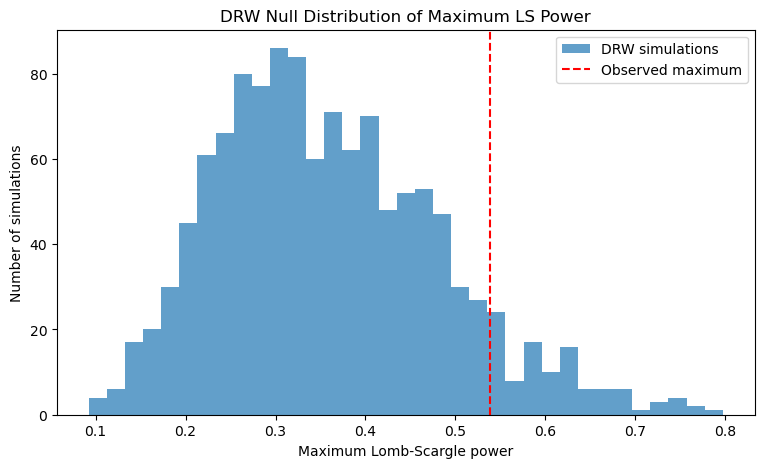


=== Tau sensitivity ===
tau = 70.4 d: p = 0.07327
tau = 105.9 d: p = 0.08410
tau = 194.4 d: p = 0.07827

=== Sinusoid + DRW model ===
Best period: 264.95 days
Maximum Delta chi^2: 12.137
Simulated exceedances: 264/1200
Look-elsewhere corrected empirical p: 0.22065


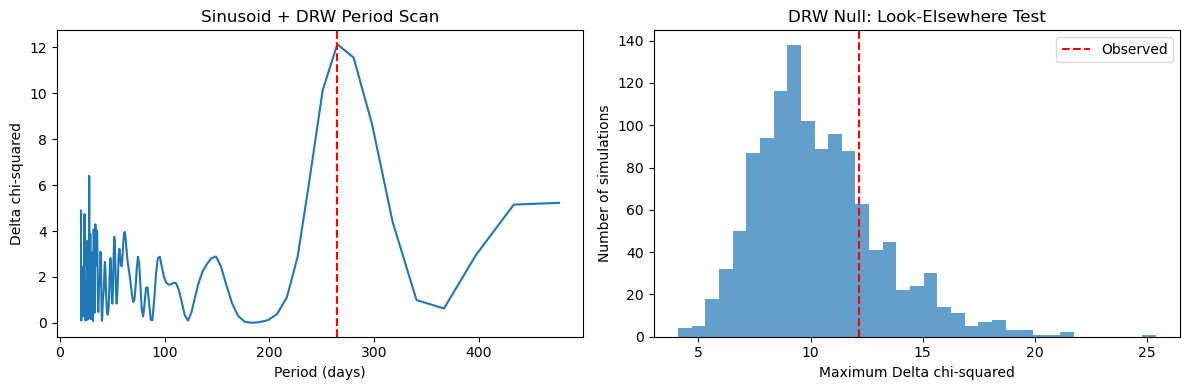


=== Candidate sinusoid ===
Period = 264.95 days
Amplitude = 0.1962 +/- 0.0565 mag
Amplitude uncertainty is conditional on fixed P, sigma, tau.

========== PART 3 FINAL RESULTS ==========
Predefined significance threshold: p < 0.01
LS empirical p-value: 0.08410
LS p at tau low: 0.07327
LS p at tau high: 0.07827
Best GLS period: 264.95 days
Best Delta chi^2: 12.137
GLS empirical p-value: 0.22065
Amplitude: 0.1962 +/- 0.0565 mag
VERDICT: Insufficient evidence for periodicity.


In [17]:
# Part 3: your work here

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cholesky, solve_triangular
from astropy.timeseries import LombScargle

rng = np.random.default_rng(457)
N_SIM = 1200

mu0 = fit_exp["mu"]
sigma0 = fit_exp["sigma"]
tau0 = fit_exp["tau"]

# Use the same frequency grid as Part 1
f_min = 2 / T
f_max = 1 / 20
df = 1 / (5 * T)
freq3 = np.arange(f_min, f_max + df / 2, df)
period3 = 1 / freq3

# Observed Lomb-Scargle statistic
observed_power = LombScargle(t, y, dy=e).power(freq3)
obs_max_power = np.max(observed_power)
obs_period = period3[np.argmax(observed_power)]

print("Observed period:", round(obs_period, 2), "days")
print("Observed maximum LS power:", round(obs_max_power, 4))

# --------------------------------
# 3.2 Simulate DRW light curves
# --------------------------------

def simulate_drw(t, e, mu, sigma, tau, nsim, rng):
    # DRW covariance WITHOUT measurement noise
    K = covariance(t, t, sigma, tau, "exp")
    L = cholesky(K, lower=True, check_finite=False)

    z = rng.standard_normal((len(t), nsim))
    measurement_noise = e[:, None] * rng.standard_normal(
        (len(t), nsim)
    )

    # Each column is one simulated light curve
    return mu + L @ z + measurement_noise

def simulate_peak_distribution(tau_value, nsim, rng):
    sims = simulate_drw(
        t, e, mu0, sigma0, tau_value, nsim, rng
    )
    max_powers = np.empty(nsim)

    for i in range(nsim):
        ls_sim = LombScargle(t, sims[:, i], dy=e)
        max_powers[i] = np.max(ls_sim.power(freq3))

    return max_powers

sim_powers = simulate_peak_distribution(
    tau0, N_SIM, rng
)

n_exceed = np.sum(sim_powers >= obs_max_power)
p_emp = (n_exceed + 1) / (N_SIM + 1)

print("\n=== Lomb-Scargle DRW Monte Carlo ===")
print(f"Number of simulations: {N_SIM}")
print(f"Exceedances: {n_exceed}")
print(f"Empirical p-value: {p_emp:.5f}")
print("Astropy white-noise FAP: 2.8193e-39")
print("Decision threshold: 0.01")

plt.figure(figsize=(9, 5))
plt.hist(sim_powers, bins=35, alpha=0.7,
         label="DRW simulations")
plt.axvline(obs_max_power, color="red", linestyle="--",
            label="Observed maximum")
plt.xlabel("Maximum Lomb-Scargle power")
plt.ylabel("Number of simulations")
plt.title("DRW Null Distribution of Maximum LS Power")
plt.legend()
plt.show()

# --------------------------------
# Sensitivity to tau uncertainty
# --------------------------------

tau_low = tau_lo
tau_high = tau_hi

powers_low = simulate_peak_distribution(
    tau_low, N_SIM, rng
)
powers_high = simulate_peak_distribution(
    tau_high, N_SIM, rng
)

p_low = (np.sum(powers_low >= obs_max_power) + 1) / (N_SIM + 1)
p_high = (np.sum(powers_high >= obs_max_power) + 1) / (N_SIM + 1)

print("\n=== Tau sensitivity ===")
print(f"tau = {tau_low:.1f} d: p = {p_low:.5f}")
print(f"tau = {tau0:.1f} d: p = {p_emp:.5f}")
print(f"tau = {tau_high:.1f} d: p = {p_high:.5f}")

# --------------------------------
# 3.3 Sinusoid + DRW GLS scan
# --------------------------------

# Fixed DRW covariance and measurement noise
C = covariance(t, t, sigma0, tau0, "exp")
C[np.diag_indices_from(C)] += e**2
L = cholesky(C, lower=True, check_finite=False)

# Whitening removes correlated DRW noise
def whiten(a):
    return solve_triangular(
        L, a, lower=True, check_finite=False
    )

ones = whiten(np.ones(len(t)))
unit_mean = ones / np.linalg.norm(ones)

def remove_mean(a):
    if a.ndim == 1:
        return a - unit_mean * (unit_mean @ a)
    return a - np.outer(unit_mean, unit_mean @ a)

# Prepare all sine and cosine basis vectors
omega = 2 * np.pi * freq3

Xcos = np.cos(np.outer(t, omega))
Xsin = np.sin(np.outer(t, omega))

U = remove_mean(whiten(Xcos))
V = remove_mean(whiten(Xsin))

# Gram matrix entries, one 2x2 matrix per period
a = np.sum(U * U, axis=0)
b = np.sum(U * V, axis=0)
c = np.sum(V * V, axis=0)
det = a * c - b**2

def scan_delta_chi2(curves):
    """
    Return max improvement in chi-square when adding
    cosine and sine terms to the constant-mean DRW.
    Each column is a separate light curve.
    """
    if curves.ndim == 1:
        curves = curves[:, None]

    residual = remove_mean(whiten(curves))
    qcos = U.T @ residual
    qsin = V.T @ residual

    improvement = (
        c[:, None] * qcos**2
        - 2 * b[:, None] * qcos * qsin
        + a[:, None] * qsin**2
    ) / det[:, None]

    best_index = np.argmax(improvement, axis=0)
    best_delta = improvement[
        best_index, np.arange(curves.shape[1])
    ]

    return best_delta, best_index, improvement

# Observed light curve
obs_delta, obs_index, delta_curve = scan_delta_chi2(y)
obs_delta = obs_delta[0]
best_index = obs_index[0]
best_period_gls = period3[best_index]

# Monte Carlo: same max statistic for simulated curves
# Process in batches to avoid storing large arrays
sim_deltas = []

batch_size = 100
for start in range(0, N_SIM, batch_size):
    size = min(batch_size, N_SIM - start)
    simulated = simulate_drw(
        t, e, mu0, sigma0, tau0, size, rng
    )
    batch_delta, _, _ = scan_delta_chi2(simulated)
    sim_deltas.extend(batch_delta)

sim_deltas = np.array(sim_deltas)

n_gls_exceed = np.sum(sim_deltas >= obs_delta)
p_gls = (n_gls_exceed + 1) / (N_SIM + 1)

print("\n=== Sinusoid + DRW model ===")
print(f"Best period: {best_period_gls:.2f} days")
print(f"Maximum Delta chi^2: {obs_delta:.3f}")
print(f"Simulated exceedances: {n_gls_exceed}/{N_SIM}")
print(f"Look-elsewhere corrected empirical p: {p_gls:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(period3, delta_curve[:, 0])
axes[0].axvline(best_period_gls, color="red",
                linestyle="--")
axes[0].set_xlabel("Period (days)")
axes[0].set_ylabel("Delta chi-squared")
axes[0].set_title("Sinusoid + DRW Period Scan")

axes[1].hist(sim_deltas, bins=35, alpha=0.7)
axes[1].axvline(obs_delta, color="red",
                linestyle="--", label="Observed")
axes[1].set_xlabel("Maximum Delta chi-squared")
axes[1].set_ylabel("Number of simulations")
axes[1].set_title("DRW Null: Look-Elsewhere Test")
axes[1].legend()

plt.tight_layout()
plt.show()

# --------------------------------
# Best sinusoidal amplitude
# --------------------------------

w = 2 * np.pi / best_period_gls
X = np.column_stack([
    np.ones_like(t),
    np.cos(w * t),
    np.sin(w * t)
])

X_white = whiten(X)
y_white = whiten(y)

G = X_white.T @ X_white
params = np.linalg.solve(G, X_white.T @ y_white)
param_cov = np.linalg.inv(G)

mu_fit, B, D = params
amplitude = np.hypot(B, D)

# Conditional amplitude uncertainty at fixed period
gradient = np.array([B, D]) / amplitude
amplitude_error = np.sqrt(
    gradient @ param_cov[1:, 1:] @ gradient
)

print("\n=== Candidate sinusoid ===")
print(f"Period = {best_period_gls:.2f} days")
print(f"Amplitude = {amplitude:.4f} +/- "
      f"{amplitude_error:.4f} mag")
print("Amplitude uncertainty is conditional on fixed P, sigma, tau.")

# --------------------------------
# Final verdict
# --------------------------------

print("\n========== PART 3 FINAL RESULTS ==========")
print(f"Predefined significance threshold: p < 0.01")
print(f"LS empirical p-value: {p_emp:.5f}")
print(f"LS p at tau low: {p_low:.5f}")
print(f"LS p at tau high: {p_high:.5f}")
print(f"Best GLS period: {best_period_gls:.2f} days")
print(f"Best Delta chi^2: {obs_delta:.3f}")
print(f"GLS empirical p-value: {p_gls:.5f}")
print(f"Amplitude: {amplitude:.4f} +/- {amplitude_error:.4f} mag")

if p_emp < 0.01 and p_gls < 0.01:
    print("VERDICT: Periodicity passes both empirical tests.")
else:
    print("VERDICT: Insufficient evidence for periodicity.")


**ANSWER (the decision rule first, then the verdict):**

### Part 3: Is It Periodic?

**1. Decision Rule**

Before running the simulations, I chose an empirical significance threshold of **p < 0.01** to claim evidence for periodicity. I chose this conservative threshold because quasars exhibit correlated red noise, which can produce strong apparent periodic signals even without true periodicity.

**2. DRW Simulations and Empirical p-value**

I generated 1,200 DRW light curves using the maximum-likelihood parameters from Part 2 (σ = 0.208 mag and τ = 105.9 days), with the original observation times and measurement errors.

The observed Lomb–Scargle periodogram has its highest peak at **264.95 days**, with a power of **0.5385**.

Out of 1,200 simulations, 100 produced a maximum peak at least as high as the observed one, giving an empirical **p-value of 0.08410**.

This is much larger than Astropy's white-noise false-alarm probability of 2.8193 × 10⁻³⁹. The difference occurs because Astropy assumes independent Gaussian noise, while DRW simulations account for correlated variability that can produce strong periodogram peaks.

Changing τ to the ends of its 68% interval gives:

- τ = 70.4 days: p = 0.07327
- τ = 105.9 days: p = 0.08410
- τ = 194.4 days: p = 0.07827

All three p-values exceed 0.01, so the result is not significant under the predefined threshold.

**3. Sinusoid + DRW Model**

I fitted a sinusoidal signal on top of the DRW model, keeping σ and τ fixed at their maximum-likelihood values.

The best-fitting period is **264.95 days**, with a sinusoidal amplitude of **0.1962 ± 0.0565 mag** (conditional on fixed period and DRW parameters).

The maximum improvement over the constant-mean DRW model is **Δχ² = 12.137**.

However, 264 out of 1,200 simulated DRW light curves produced an equal or greater maximum improvement, giving a look-elsewhere-corrected empirical **p-value of 0.22065**.

This indicates that the apparent sinusoidal signal can plausibly arise from stochastic DRW variability rather than genuine periodicity.

**4. Final Verdict**

Neither empirical test meets my predefined significance threshold of p < 0.01:

- Lomb–Scargle empirical p-value = **0.08410**
- Sinusoid + DRW empirical p-value = **0.22065**

Therefore, I find **insufficient evidence for a genuine periodic signal** in this quasar.

Although the light curve shows an apparent period near 265 days, the signal is not statistically significant once correlated red noise and the look-elsewhere effect are considered.

Stronger evidence would require additional observing seasons showing a stable, coherent periodic signal that remains statistically significant under a DRW noise model.

**Should the team announce a binary candidate?**

No. The team should not announce a supermassive black hole binary candidate based on the current evidence, because the observed variability can be explained by stochastic quasar noise.

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


ERROR 1: PERIOD SIGNIFICANCE
White-noise FAP: 2.0996e-40
DRW Lomb-Scargle empirical p: 0.08410
Sinusoid + DRW empirical p: 0.22065
Threshold: p < 0.01
Correct conclusion: no significant periodicity

ERROR 2: KERNEL SELECTION
Exponential logL: 338.422
Squared-exponential logL: 300.311
Delta logL: 38.111
Exponential sigma: 0.208
Exponential tau: 105.9 days
Squared-exp sigma: 0.180
Squared-exp ell: 10.0 days

ERROR 3: VALIDATION
AI: random 5-fold, full-data hyperparameters
Squared-exp coverage: 59.8%
Squared-exp R2: 0.934

Independent 30-day block validation:
Squared-exp coverage: 51.1%
Squared-exp R2: 0.699
Exponential coverage: 66.0%
Exponential R2: 0.884


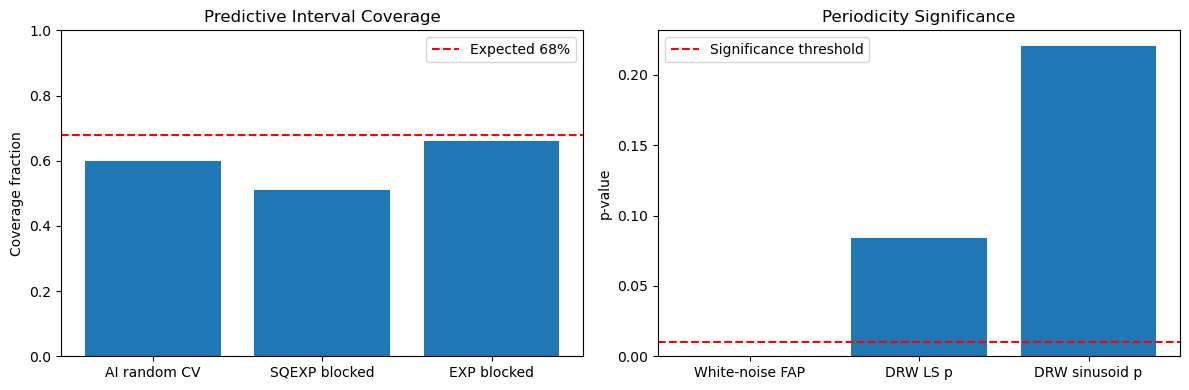


========== REFEREE SUMMARY ==========
White-noise FAP: 2.100e-40
Correct DRW p: 0.08410
Correct GLS p: 0.22065
Kernel difference: 38.111
AI random CV coverage: 59.8%
Blocked SQEXP coverage: 51.1%
Blocked EXP coverage: 66.0%


In [18]:
# Part 4: your work here

# =============================================
# PART 4: REFEREE REPORT
# Reproducing and testing the AI's mistakes
# =============================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ---------------------------------------------
# ERROR 1: White noise vs DRW significance
# ---------------------------------------------

white_fap = ls.false_alarm_probability(
    best_power,
    minimum_frequency=f_min,
    maximum_frequency=f_max
)

print("ERROR 1: PERIOD SIGNIFICANCE")
print(f"White-noise FAP: {white_fap:.4e}")
print(f"DRW Lomb-Scargle empirical p: {p_emp:.5f}")
print(f"Sinusoid + DRW empirical p: {p_gls:.5f}")
print("Threshold: p < 0.01")
print("Correct conclusion: no significant periodicity")

# ---------------------------------------------
# ERROR 2: Wrong GP kernel assumption
# ---------------------------------------------

print("\nERROR 2: KERNEL SELECTION")
print(f"Exponential logL: {fit_exp['logL']:.3f}")
print(f"Squared-exponential logL: {fit_sq['logL']:.3f}")
print(f"Delta logL: {delta_logL:.3f}")
print(f"Exponential sigma: {fit_exp['sigma']:.3f}")
print(f"Exponential tau: {fit_exp['tau']:.1f} days")
print(f"Squared-exp sigma: {fit_sq['sigma']:.3f}")
print(f"Squared-exp ell: {fit_sq['tau']:.1f} days")

# ---------------------------------------------
# ERROR 3: Random CV with data leakage
# Reproduce the AI's validation procedure
# ---------------------------------------------

rng_ai = np.random.default_rng(1)
folds_ai = rng_ai.permutation(len(t)) % 5

pred_ai = np.empty(len(t))
std_ai = np.empty(len(t))

# The AI fits hyperparameters on ALL data first
full_fit_ai = fit_gp(t, y, e, "sqexp")

for k in range(5):
    test_mask = folds_ai == k
    train_mask = ~test_mask

    # Intentionally use full-data hyperparameters,
    # reproducing the AI's information leakage.
    mean, std = gp_predict(
        t[train_mask],
        y[train_mask],
        e[train_mask],
        t[test_mask],
        full_fit_ai,
        "sqexp",
        e_pred=e[test_mask]
    )

    pred_ai[test_mask] = mean
    std_ai[test_mask] = std

ai_coverage = np.mean(np.abs(y - pred_ai) <= std_ai)
ai_r2 = 1 - np.sum((y - pred_ai)**2) / np.sum((y - y.mean())**2)

# Our independent blocked validation from Part 2
blocked_coverage_sq = sq_cv[3]
blocked_r2_sq = sq_cv[4]
blocked_coverage_exp = exp_cv[3]
blocked_r2_exp = exp_cv[4]

print("\nERROR 3: VALIDATION")
print("AI: random 5-fold, full-data hyperparameters")
print(f"Squared-exp coverage: {ai_coverage:.1%}")
print(f"Squared-exp R2: {ai_r2:.3f}")

print("\nIndependent 30-day block validation:")
print(f"Squared-exp coverage: {blocked_coverage_sq:.1%}")
print(f"Squared-exp R2: {blocked_r2_sq:.3f}")
print(f"Exponential coverage: {blocked_coverage_exp:.1%}")
print(f"Exponential R2: {blocked_r2_exp:.3f}")

# ---------------------------------------------
# Plot the comparisons
# ---------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = ["AI random CV", "SQEXP blocked",
          "EXP blocked"]
values = [ai_coverage, blocked_coverage_sq,
          blocked_coverage_exp]

axes[0].bar(labels, values)
axes[0].axhline(0.68, color="red", linestyle="--",
                label="Expected 68%")
axes[0].set_ylabel("Coverage fraction")
axes[0].set_ylim(0, 1)
axes[0].set_title("Predictive Interval Coverage")
axes[0].legend()

labels2 = ["White-noise FAP", "DRW LS p",
           "DRW sinusoid p"]
values2 = [white_fap, p_emp, p_gls]

axes[1].bar(labels2, values2)
axes[1].axhline(0.01, color="red", linestyle="--",
                label="Significance threshold")
axes[1].set_ylabel("p-value")
axes[1].set_title("Periodicity Significance")
axes[1].legend()

plt.tight_layout()
plt.show()

print("\n========== REFEREE SUMMARY ==========")
print(f"White-noise FAP: {white_fap:.3e}")
print(f"Correct DRW p: {p_emp:.5f}")
print(f"Correct GLS p: {p_gls:.5f}")
print(f"Kernel difference: {delta_logL:.3f}")
print(f"AI random CV coverage: {ai_coverage:.1%}")
print(f"Blocked SQEXP coverage: {blocked_coverage_sq:.1%}")
print(f"Blocked EXP coverage: {blocked_coverage_exp:.1%}")


**REFEREE REPORT:**

**Overall assessment: Major Revision**

The AI solution runs successfully but contains several substantive statistical errors that lead to an unsupported claim of periodicity.

### 1. Incorrect Significance Test

The AI claims a highly significant periodic signal based on the Lomb–Scargle false-alarm probability, which assumes white noise. However, quasar variability is correlated and better described by a damped random walk (DRW).

For my dataset, the white-noise FAP is approximately **2.100 × 10⁻⁴⁰**. However, simulations of 1,200 DRW light curves give an empirical p-value of **0.08410**. A sinusoid-plus-DRW model gives a look-elsewhere-corrected empirical p-value of **0.22065**.

Both values exceed my predefined threshold of 0.01. Therefore, the apparent periodicity is not statistically significant.

**Correction:** Use DRW simulations with the actual observation times and measurement errors, and compare the maximum period-search statistic to the simulated distribution.

### 2. Inappropriate Gaussian-Process Kernel

The AI assumes that quasar variability is smooth and uses a squared-exponential kernel without comparing it against an exponential DRW kernel.

I fitted both models and found that the exponential kernel has a higher maximum log-likelihood by **Δ ln L = 38.111**. Because both kernels have the same number of parameters, this strongly favors the exponential kernel in maximum likelihood.

The exponential kernel allows rougher stochastic variability, while the squared-exponential kernel imposes much smoother behavior.

**Correction:** Fit and compare both kernels instead of selecting one based on an assumption of smoothness.

### 3. Cross-Validation and Data Leakage

The AI performs random five-fold cross-validation but estimates the GP hyperparameters using the complete dataset before dividing it into training and validation sets. This leaks information from the held-out observations into the fitted model.

Random validation also places test observations close to training observations, making interpolation easier than prediction over extended gaps.

My results show:

| Validation method | 68% band coverage |
|---|---|
| AI-style random five-fold CV (squared-exponential) | 59.8% |
| Blocked CV (squared-exponential) | 51.1% (24/47) |
| Blocked CV (exponential) | 66.0% (31/47) |

The squared-exponential coverage decreases from 59.8% to 51.1% when using independent temporal blocks. The exponential kernel achieves coverage much closer to the expected 68%.

This demonstrates that the AI's validation procedure gives a more favorable impression of predictive performance and does not adequately test prediction across observing gaps.

**Correction:** Hold out consecutive time blocks, refit the GP parameters using only the training data, and include measurement noise when evaluating the predictive intervals.

### 4. Inappropriate Uncertainty Estimates

The AI estimates the GP correlation-length uncertainty from the local curvature of the likelihood while holding the other parameters fixed. This neglects correlations between parameters and assumes symmetric, approximately Gaussian uncertainties.

It also estimates the periodicity uncertainty using a white-noise sinusoidal approximation, even though the observed variability is time-correlated.

My exponential DRW profile-likelihood analysis gives:

**τ = 105.9 (+88.5 / −35.5) days.**

The uncertainties are clearly asymmetric, illustrating why a symmetric local-curvature approximation can be misleading. This does not directly quantify the error in the AI's squared-exponential length-scale uncertainty, which would require profiling that kernel separately.

**Correction:** Use profile likelihoods or posterior sampling that accounts for parameter correlations and asymmetric uncertainties. Period uncertainties should also be calculated under a correlated-noise model.

### Final Assessment

The AI solution incorrectly interprets the Lomb–Scargle peak as strong evidence of periodicity, uses a less suitable GP kernel, and relies on an inadequate validation procedure.

Although the light curve shows a prominent peak near 265 days, the empirical significance tests under a DRW noise model do not support a genuine periodic signal.

**I recommend rejecting the AI solution's conclusion that this quasar should be announced as a supermassive black hole binary candidate.** More observations and a statistically significant periodic signal under correlated-noise modeling would be required.

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [23]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

OID = 'ZTF19abujzxs'
mjd, mag, merr = get_ztf_g(OID)

print(f"{OID}: {len(mjd)} observations")
print(f"Time span: {(mjd.max() - mjd.min()) / 365.25:.2f} years")
print(f"Last detection: MJD {mjd.max():.1f}")
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF19abujzxs: 676 g-band detections from the live API
ZTF19abujzxs: 676 observations
Time span: 5.55 years
Last detection: MJD 61059.1
ZTF19abujzxs: MJD 59033.5 to 61059.1 (5.5 yr); the last detection is MJD 61059.1; today is MJD 61340


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


In [ ]:
#Decision rule:
#I will use the same significance threshold as in Part 3: an empirical p-value below 0.01. I will claim 
#evidence for periodicity only if both the Lomb–Scargle DRW Monte Carlo test and the sinusoid-plus-
#DRW test satisfy this threshold, accounting for correlated red noise and the look-elsewhere effect. I 
#will not change this rule after examining the results.

Number of original observations: 676
Number of nightly averages: 461
Time span: 2025.7 days


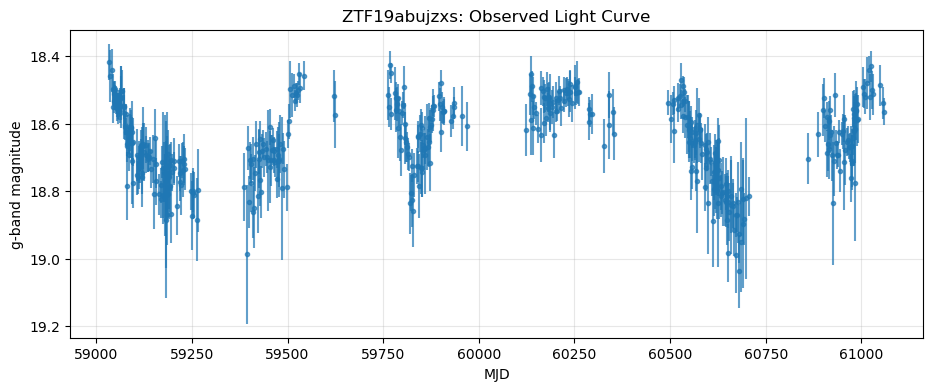


=== ZTF DRW fit ===
mu = 18.6040
sigma = 0.1113 mag
tau = 212.33 days

=== Observed periodogram ===
Best period: 723.45 days
Maximum LS power: 0.3646


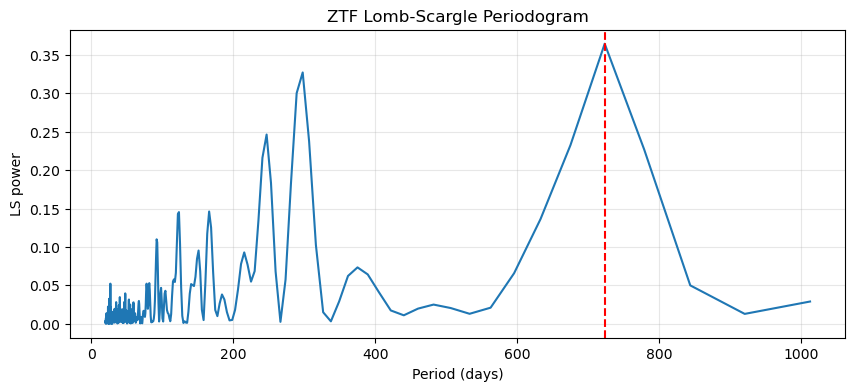


=== DRW Lomb-Scargle test ===
Exceedances: 530/1200
Empirical p-value: 0.44213


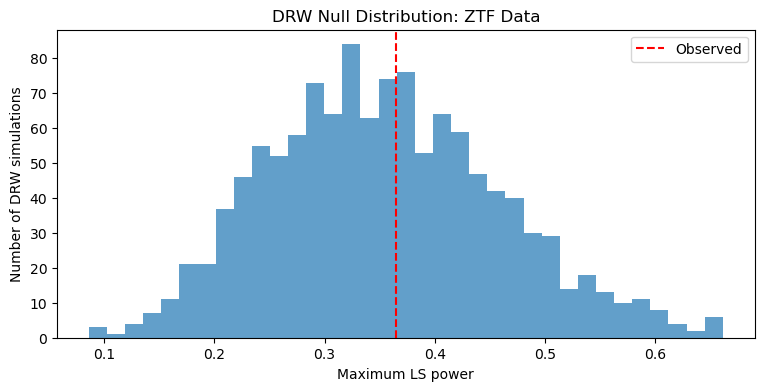


=== Sinusoid + DRW test ===
Best period: 723.45 days
Maximum Delta chi^2: 12.832
Exceedances: 375/1200
Empirical p-value: 0.31307

=== Sampling information ===
Median cadence: 1.98 days
Largest observing gap: 154.3 days
Last observation MJD: 61059.1

========== PART 5 FINAL RESULTS ==========
Nightly epochs: 461
DRW sigma: 0.1113 mag
DRW tau: 212.33 days
LS best period: 723.45 days
LS empirical p: 0.44213
GLS best period: 723.45 days
GLS empirical p: 0.31307
Median cadence: 1.98 days
Last detection MJD: 61059.1
VERDICT: Insufficient evidence for periodicity.


In [24]:
# Part 5: your work here

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.linalg import cholesky, solve_triangular
from scipy.optimize import minimize
from astropy.timeseries import LombScargle

# 1. Clean the actual ZTF observations
good = (
    np.isfinite(mjd) & np.isfinite(mag) &
    np.isfinite(merr) & (merr > 0)
)
mjd5, mag5, err5 = mjd[good], mag[good], merr[good]

# 2. Weighted nightly averages
night = np.floor(mjd5).astype(int)
nights = np.unique(night)

t5, y5, e5 = [], [], []

for n in nights:
    mask = night == n
    weights = 1 / err5[mask]**2

    t5.append(np.average(mjd5[mask], weights=weights))
    y5.append(np.average(mag5[mask], weights=weights))
    e5.append(np.sqrt(1 / weights.sum()))

t5 = np.array(t5)
y5 = np.array(y5)
e5 = np.array(e5)

order = np.argsort(t5)
t5, y5, e5 = t5[order], y5[order], e5[order]

T5 = np.ptp(t5)

print("Number of original observations:", len(mjd5))
print("Number of nightly averages:", len(t5))
print(f"Time span: {T5:.1f} days")

plt.figure(figsize=(11, 4))
plt.errorbar(t5, y5, yerr=e5, fmt=".",
             alpha=0.7)
plt.gca().invert_yaxis()
plt.xlabel("MJD")
plt.ylabel("g-band magnitude")
plt.title("ZTF19abujzxs: Observed Light Curve")
plt.grid(alpha=0.3)
plt.show()

# 3. Fit DRW to the real light curve
# Reuse fit_gp and covariance from Part 2
fit5 = fit_gp(t5, y5, e5, "exp")

print("\n=== ZTF DRW fit ===")
print(f"mu = {fit5['mu']:.4f}")
print(f"sigma = {fit5['sigma']:.4f} mag")
print(f"tau = {fit5['tau']:.2f} days")

# 4. Observed Lomb-Scargle periodogram
f5 = np.arange(
    2 / T5, 1 / 20,
    1 / (5 * T5)
)

period5 = 1 / f5

ls5 = LombScargle(t5, y5, dy=e5)
power5 = ls5.power(f5)

observed_ls5 = np.max(power5)
best_period5 = period5[np.argmax(power5)]

print("\n=== Observed periodogram ===")
print(f"Best period: {best_period5:.2f} days")
print(f"Maximum LS power: {observed_ls5:.4f}")

plt.figure(figsize=(10, 4))
plt.plot(period5, power5)
plt.axvline(best_period5, color="red", linestyle="--")
plt.xlabel("Period (days)")
plt.ylabel("LS power")
plt.title("ZTF Lomb-Scargle Periodogram")
plt.grid(alpha=0.3)
plt.show()

# 5. Simulate DRW light curves
rng5 = np.random.default_rng(457)
N5 = 1200

mu5 = fit5["mu"]
sigma5 = fit5["sigma"]
tau5 = fit5["tau"]

K5 = covariance(t5, t5, sigma5, tau5, "exp")
L5 = cholesky(K5, lower=True, check_finite=False)

# Generate simulations in batches
sim_peak5 = []
batch_size = 50

for start in range(0, N5, batch_size):
    batch = min(batch_size, N5 - start)

    z = rng5.standard_normal((len(t5), batch))
    noise = e5[:, None] * rng5.standard_normal(
        (len(t5), batch)
    )

    sims = mu5 + L5 @ z + noise

    for j in range(batch):
        simulated_ls = LombScargle(
            t5, sims[:, j], dy=e5
        ).power(f5)
        sim_peak5.append(np.max(simulated_ls))

sim_peak5 = np.array(sim_peak5)

n_ls5 = np.sum(sim_peak5 >= observed_ls5)
p_ls5 = (n_ls5 + 1) / (N5 + 1)

print("\n=== DRW Lomb-Scargle test ===")
print(f"Exceedances: {n_ls5}/{N5}")
print(f"Empirical p-value: {p_ls5:.5f}")

plt.figure(figsize=(9, 4))
plt.hist(sim_peak5, bins=35, alpha=0.7)
plt.axvline(observed_ls5, color="red",
            linestyle="--", label="Observed")
plt.xlabel("Maximum LS power")
plt.ylabel("Number of DRW simulations")
plt.legend()
plt.title("DRW Null Distribution: ZTF Data")
plt.show()

# 6. Sinusoid + DRW likelihood-ratio test
C5 = K5.copy()
C5[np.diag_indices_from(C5)] += e5**2
Lobs5 = cholesky(C5, lower=True, check_finite=False)

def whiten5(a):
    return solve_triangular(
        Lobs5, a, lower=True, check_finite=False
    )

one5 = whiten5(np.ones(len(t5)))
one5 /= np.linalg.norm(one5)

def demean5(a):
    if a.ndim == 1:
        return a - one5 * (one5 @ a)
    return a - np.outer(one5, one5 @ a)

omega5 = 2 * np.pi * f5

U5 = demean5(whiten5(np.cos(np.outer(t5, omega5))))
V5 = demean5(whiten5(np.sin(np.outer(t5, omega5))))

a5 = np.sum(U5**2, axis=0)
b5 = np.sum(U5 * V5, axis=0)
c5 = np.sum(V5**2, axis=0)
det5 = a5 * c5 - b5**2

def delta_chi2_5(curves):
    if curves.ndim == 1:
        curves = curves[:, None]

    r = demean5(whiten5(curves))
    qc = U5.T @ r
    qs = V5.T @ r

    delta = (
        c5[:, None] * qc**2
        - 2 * b5[:, None] * qc * qs
        + a5[:, None] * qs**2
    ) / det5[:, None]

    best_idx = np.argmax(delta, axis=0)
    best = delta[best_idx, np.arange(curves.shape[1])]

    return best, best_idx

obs_delta5, obs_idx5 = delta_chi2_5(y5)
obs_delta5 = obs_delta5[0]

gls_period5 = period5[obs_idx5[0]]

# Monte Carlo under DRW
sim_delta5 = []

for start in range(0, N5, batch_size):
    batch = min(batch_size, N5 - start)

    z = rng5.standard_normal((len(t5), batch))
    noise = e5[:, None] * rng5.standard_normal(
        (len(t5), batch)
    )

    sims = mu5 + L5 @ z + noise
    best, _ = delta_chi2_5(sims)
    sim_delta5.extend(best)

sim_delta5 = np.array(sim_delta5)

n_gls5 = np.sum(sim_delta5 >= obs_delta5)
p_gls5 = (n_gls5 + 1) / (N5 + 1)

print("\n=== Sinusoid + DRW test ===")
print(f"Best period: {gls_period5:.2f} days")
print(f"Maximum Delta chi^2: {obs_delta5:.3f}")
print(f"Exceedances: {n_gls5}/{N5}")
print(f"Empirical p-value: {p_gls5:.5f}")

# 7. Sampling characteristics
gaps5 = np.diff(t5)

print("\n=== Sampling information ===")
print(f"Median cadence: {np.median(gaps5):.2f} days")
print(f"Largest observing gap: {np.max(gaps5):.1f} days")
print(f"Last observation MJD: {t5.max():.1f}")

# 8. Final verdict
print("\n========== PART 5 FINAL RESULTS ==========")
print(f"Nightly epochs: {len(t5)}")
print(f"DRW sigma: {sigma5:.4f} mag")
print(f"DRW tau: {tau5:.2f} days")
print(f"LS best period: {best_period5:.2f} days")
print(f"LS empirical p: {p_ls5:.5f}")
print(f"GLS best period: {gls_period5:.2f} days")
print(f"GLS empirical p: {p_gls5:.5f}")
print(f"Median cadence: {np.median(gaps5):.2f} days")
print(f"Last detection MJD: {t5.max():.1f}")

if p_ls5 < 0.01 and p_gls5 < 0.01:
    print("VERDICT: Evidence for periodicity under the chosen rule.")
else:
    print("VERDICT: Insufficient evidence for periodicity.")


**ANSWER (the criterion first, then the result):**

**Criterion:** Before running the analysis, I required both DRW-based empirical p-values to be below 0.01 to claim evidence for periodicity, accounting for correlated noise and the look-elsewhere effect.

**Result:** The strongest candidate period is **723.45 days**, with a DRW Lomb–Scargle empirical p-value of **0.44213** and a sinusoid-plus-DRW empirical p-value of **0.31307**. Both exceed 0.01, so there is **insufficient evidence for periodicity** under my predefined criterion.

**Sampling and next steps:** Unlike the simulated light curve, this real ZTF dataset spans 5.55 years with 461 nightly epochs, a median cadence of 1.98 days, irregular sampling, and seasonal gaps. The last detection was MJD 61059.1, approximately 281 days before the notebook's reference date. With one more week, I would check for newer observations, investigate the long observational gap, and repeat the DRW-based significance tests to determine whether the candidate period remains coherent.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


### AI-USE APPENDIX

I used ChatGPT (GPT-6) to help write and explain Python code for the Lomb–Scargle periodogram, Gaussian-process modeling, Monte Carlo simulations, and statistical comparisons. I also used it to help interpret the numerical results and organize the referee report.

One important limitation of the AI assistance was that the initial periodogram analysis relied on Astropy's white-noise false-alarm probability, which could have been misleading for a quasar with correlated variability. I identified this problem by comparing the extremely small white-noise FAP with empirical p-values obtained from DRW simulations.

I also checked the AI-generated code by running it on my dataset, inspecting the resulting plots, and comparing the exponential and squared-exponential kernels. The exponential kernel gave a higher maximum log-likelihood by 38.111, and its blocked-validation coverage was closer to the expected 68%.

### REFLECTION

Without checking the AI-assisted analysis, I might have incorrectly concluded that the quasar contains a statistically significant periodic signal near 265 days based on the extremely small white-noise FAP.

However, the DRW Monte Carlo analysis gave p = 0.08410, and the sinusoid-plus-DRW test gave p = 0.22065. Both exceeded my predefined significance threshold of 0.01.

This demonstrates that code running successfully and producing convincing plots does not guarantee statistically valid conclusions. The assumed noise model and the method used to calculate significance are essential.

### VERIFICATION PLAN

**1. Gaussian-process fitting and convergence**

I fitted the DRW model using multiple starting points to reduce the risk of finding a local maximum. I used profile likelihoods to estimate 68% intervals for σ and τ rather than relying on symmetric uncertainties.

The resulting estimates were σ = 0.208 (+0.071/−0.036) mag and τ = 105.9 (+88.5/−35.5) days.

Before trusting these results, I would check that different starting points converge to the same maximum log-likelihood and that the profile intervals are not artificially truncated by the prior boundaries. A failure would be inconsistent optimized likelihoods, unstable parameter estimates, or confidence intervals reaching the parameter bounds without closing.

**2. Predictive validation**

I tested both Gaussian-process kernels by withholding four non-overlapping 30-day blocks and refitting on the remaining observations.

The exponential kernel included 31/47 (66.0%) held-out points inside its nominal 68% predictive band, compared with 24/47 (51.1%) for the squared-exponential kernel.

A potential failure would be substantially lower coverage than the nominal 68%, suggesting that predictive uncertainties are too narrow or the model does not describe the variability adequately. Coverage from only 47 held-out observations is a diagnostic rather than a definitive calibration result.

**3. Periodicity significance**

I generated 1,200 DRW light curves using the fitted parameters, actual observing epochs, and measurement errors. I compared the observed maximum Lomb–Scargle power and maximum sinusoid-plus-DRW improvement against the corresponding simulated distributions.

The empirical p-values were 0.08410 and 0.22065, respectively, both above the predefined 0.01 threshold.

A failure of the significance procedure would occur if it frequently identified periodicity in light curves generated without a periodic signal.

**4. Synthetic-data recovery test (proposed additional verification)**

I would generate synthetic DRW light curves using known σ and τ values at the same observation times and with the same measurement errors as my dataset.

First, I would generate data without a sinusoid, fit the DRW model, and verify whether the recovered parameters are consistent with the input values and whether the 68% intervals contain the true parameters.

Next, I would add a sinusoidal signal with a known period and amplitude, then run the entire fitting and periodicity-testing pipeline again. I would examine whether the period is recovered and whether the empirical significance test correctly detects the injected signal.

Failures would include confidence intervals missing the input parameters, frequent false detections in DRW-only simulations, or failure to recover sufficiently strong injected sinusoidal signals.

One synthetic realization is only a spot check. For a meaningful calibration, I would use at least **1,000 independent realizations** for the no-sinusoid case and approximately 1,000 for each selected sinusoidal amplitude. This would allow me to estimate the false-positive rate, detection power, and parameter-interval coverage, with Monte Carlo uncertainty.

Overall, these checks would help establish whether the pipeline produces reliable parameter uncertainties and periodicity claims rather than merely plausible-looking results.